## Egyptian pharmaceutical drugs EDA

In [1]:
#import libraries
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#read data
eg = pd.read_csv("https://raw.githubusercontent.com/mahmoudfalous/eg-drugs/main/data/eg_drugs.csv")

In [3]:
#show
eg.head()

,id,name,arabic,active,company,price,oldprice,availability,barcode,slug,...,uses_summary_en,warning_high_blood_pressure,warning_diabetes,warning_pregnancy,warning_lactation,warning_kidney,warning_liver,warning_heart,warnings_summary,warnings_summary_en
0,1,1 2 3 (one two three) syrup 120 ml,ون تو ثري شراب 120 مل,Chlorpheniramine+paracetamol+pseudoephedrine,Hikma,40.00.,32.00.,NaN,6221000000010,1,...,temporarily relieves nasal congestion due to t...,1,1,1,1,0,0,1,يحذر أو يوصى بالحذر تحت إشراف طبي في الحالات ا...,Caution or warning advised under medical super...
1,2,1 2 3 (one two three) 20 f.c.tabs,ون تو ثري 20 قرص,Chlorpheniramine+paracetamol+pseudoephedrine,Hikma,40.00.,24.00.,NaN,6221000000010,2,...,temporarily relieves nasal congestion due to t...,1,1,1,1,0,0,1,يحذر أو يوصى بالحذر تحت إشراف طبي في الحالات ا...,Caution or warning advised under medical super...
2,3,5-fluorouracil-ebewe 250mg/5ml i.v. vial,فلورويوراسيل 250مجم/5مل فيال وريد,Fluorouracil,Shanghai xudong haipu pharmaceutical > acdima ...,74.00.,50.00.,NaN,9088881320685,3,...,Fluorouracil Cream is recommended for the topi...,0,0,1,0,0,0,0,يحذر أو يوصى بالحذر تحت إشراف طبي في الحالات ا...,Caution or warning advised under medical super...
3,4,mooagar sachets,مو اجار 2جم اكياس,agar,hexa pharma company,75,NaN,3710.0,NaN,mooagar-sachets,...,No registered indications.,0,0,0,0,0,0,0,لا توجد تحذيرات خاصة مسجلة لهذه الحالات. استشر...,No special warnings registered for these condi...
4,5,limitless lactoferrin 100 mg 30 sachets,ليمتلس لاكتوفيرين 100 مجم 30 كيس,lactoferrin,eva pharma,485,385,3711.0,NaN,limitless-lactoferrin-100-mg-30-sachets,...,No registered indications.,0,0,0,0,0,0,0,لا توجد تحذيرات خاصة مسجلة لهذه الحالات. استشر...,No special warnings registered for these condi...


In [4]:
#data information
eg.info()

<class 'pandas.DataFrame'>
RangeIndex: 26562 entries, 0 to 26561
Data columns (total 25 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id                           26562 non-null  int64  
 1   name                         26562 non-null  str    
 2   arabic                       26562 non-null  str    
 3   active                       23805 non-null  str    
 4   company                      26252 non-null  str    
 5   price                        26557 non-null  str    
 6   oldprice                     11362 non-null  str    
 7   availability                 26219 non-null  float64
 8   barcode                      10532 non-null  str    
 9   slug                         26561 non-null  str    
 10  units                        26562 non-null  int64  
 11  description                  25427 non-null  str    
 12  uses                         8107 non-null   str    
 13  matched_fda_ingredients    

In [5]:
#count null
eg.isnull().sum()

id                                 0
name                               0
arabic                             0
active                          2757
company                          310
price                              5
oldprice                       15200
availability                     343
barcode                        16030
slug                               1
units                              0
description                     1135
uses                           18455
matched_fda_ingredients         6980
uses_summary                       0
uses_summary_en                    0
warning_high_blood_pressure        0
warning_diabetes                   0
warning_pregnancy                  0
warning_lactation                  0
warning_kidney                     0
warning_liver                      0
warning_heart                      0
warnings_summary                   0
warnings_summary_en                0
dtype: int64

In [6]:
#drop unimportant coulmns
eg = eg.drop(columns=["id", "oldprice", "barcode", "company" ,"uses" , "units" ,"uses_summary_en" ,"warnings_summary_en" , "availability"])

In [7]:
#translate price values from str to float and remove "."
eg['price'] = eg['price'].astype(str).str.rstrip('.')
eg['price'] = pd.to_numeric(eg['price'], errors='coerce')

In [8]:
#numeric columns describe
eg.describe()

,price,warning_high_blood_pressure,warning_diabetes,warning_pregnancy,warning_lactation,warning_kidney,warning_liver,warning_heart
count,2.655700e+04,26562.000000,26562.000000,26562.000000,26562.000000,26562.000000,26562.000000,26562.000000
mean,1.910563e+03,0.121075,0.117950,0.265831,0.164784,0.234470,0.153302,0.199458
std,2.087293e+05,0.326221,0.322556,0.441783,0.370993,0.423675,0.360285,0.399600
min,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.200000e+01,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,7.900000e+01,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.800000e+02,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
max,3.400000e+07,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [9]:
#find if any negative or zero values in price col
(eg['price']<=0) .sum()

np.int64(122)

In [10]:
#remove rows with zero or negative price
eg = eg[eg['price'] > 0]

In [11]:
#fill nulls in text cols 
text_cols = ['active', 'description', 'matched_fda_ingredients', 'slug']
eg[text_cols] = eg[text_cols].fillna('notfound')

In [12]:
#clean text columns
for col in ['name', 'active', 'description']:
    eg[col] = eg[col].astype(str).str.strip().str.lower()

In [13]:
#drop duplicates
eg = eg.drop_duplicates()

In [14]:
#calculate outliers for price col

Q1 = eg["price"].quantile(0.25)
Q3 = eg["price"].quantile(0.75)
IQR = Q3 - Q1
    
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
    
outliers_count = len(eg[(eg["price"] < lower_bound) | (eg["price"] > upper_bound)])
    
print(f"{"price"}: {outliers_count} Outliers")

price: 2310 Outliers


In [15]:
#drop duplicate drug names and keep the first one
eg = eg.drop_duplicates(subset='name', keep='first')

In [16]:
#final data info
eg.info()

<class 'pandas.DataFrame'>
Index: 26430 entries, 0 to 26561
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   name                         26430 non-null  str    
 1   arabic                       26430 non-null  str    
 2   active                       26430 non-null  str    
 3   price                        26430 non-null  float64
 4   slug                         26430 non-null  str    
 5   description                  26430 non-null  str    
 6   matched_fda_ingredients      26430 non-null  str    
 7   uses_summary                 26430 non-null  str    
 8   warning_high_blood_pressure  26430 non-null  int64  
 9   warning_diabetes             26430 non-null  int64  
 10  warning_pregnancy            26430 non-null  int64  
 11  warning_lactation            26430 non-null  int64  
 12  warning_kidney               26430 non-null  int64  
 13  warning_liver                264

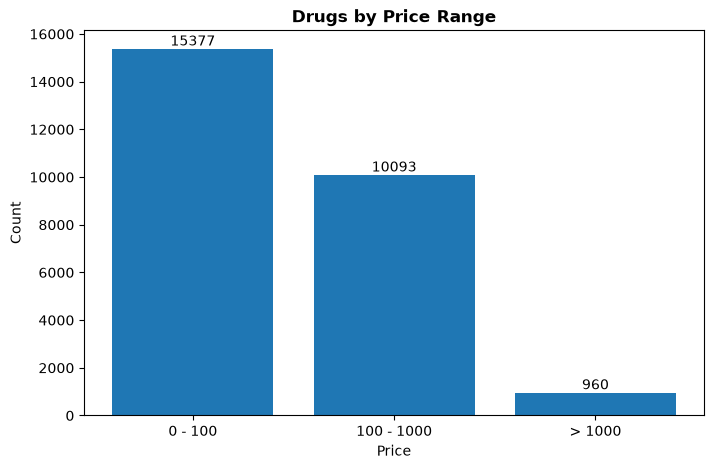

In [17]:
#visualization
%matplotlib inline

price_cat = pd.cut(eg['price'], bins=[0, 100, 1000, float('inf')],
labels=['0 - 100', '100 - 1000', '> 1000'], include_lowest=True)
price_counts = price_cat.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(price_counts.index.astype(str), price_counts.values)
ax.bar_label(bars)
ax.set_title('Drugs by Price Range', fontsize=12, fontweight='bold')
ax.set_xlabel('Price')
ax.set_ylabel('Count')
plt.show()

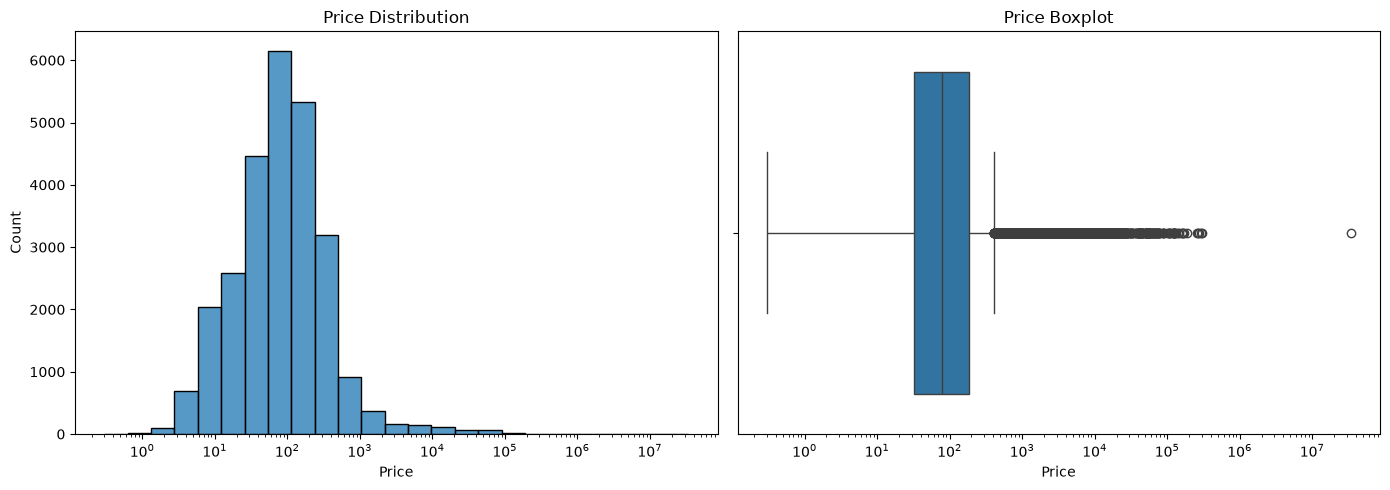

In [18]:
#price distribution using log scale because of heavy skew
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(eg['price'], bins=25, log_scale=True, ax=axes[0])
axes[0].set_title('Price Distribution')
axes[0].set_xlabel('Price')

sns.boxplot(x=eg['price'], ax=axes[1])
axes[1].set_xscale('log')
axes[1].set_title('Price Boxplot')
axes[1].set_xlabel('Price')

plt.tight_layout()
plt.show()

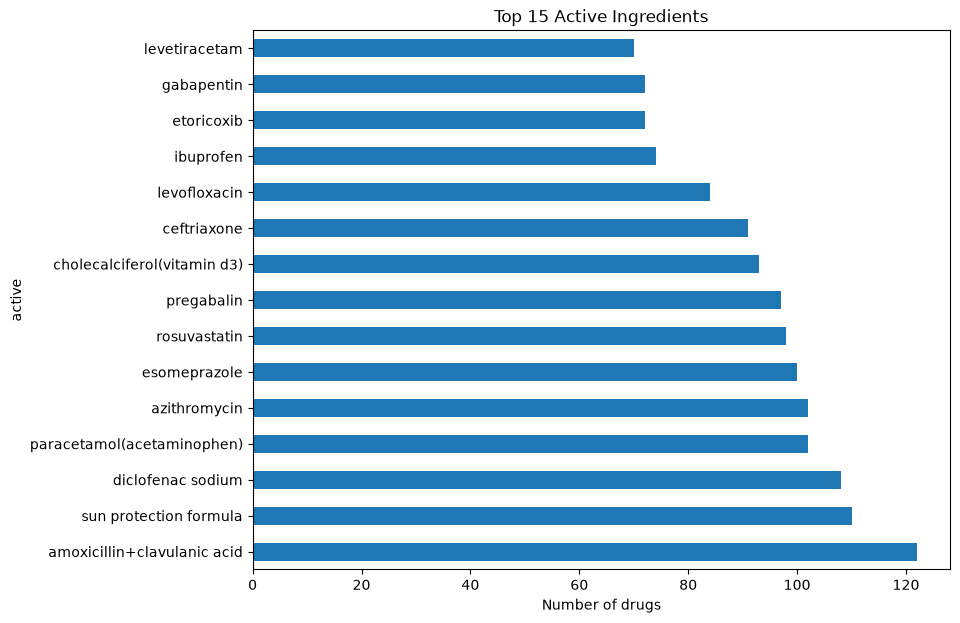

In [19]:
#top 15 active ingredients
active_counts = eg[eg['active'] != 'notfound']['active'].value_counts().head(15)

active_counts.plot(kind='barh', figsize=(9, 7))
plt.title('Top 15 Active Ingredients')
plt.xlabel('Number of drugs')
plt.show()

In [20]:
print("Unique active ingredients:", eg[eg['active'] != 'notfound']['active'].nunique())

Unique active ingredients: 8946


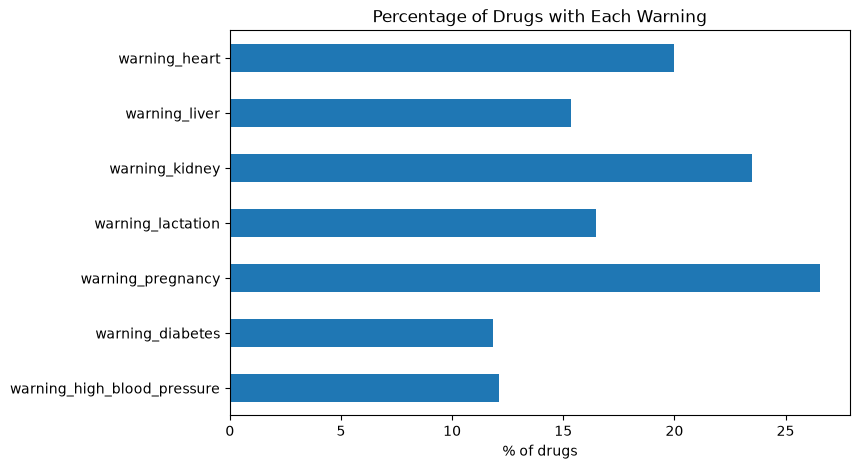

In [21]:
warning_cols = ['warning_high_blood_pressure', 'warning_diabetes', 'warning_pregnancy',
                'warning_lactation', 'warning_kidney', 'warning_liver', 'warning_heart']

warn_pct = eg[warning_cols].mean() * 100

warn_pct.plot(kind='barh', figsize=(8, 5))
plt.title('Percentage of Drugs with Each Warning')
plt.xlabel('% of drugs')
plt.show()

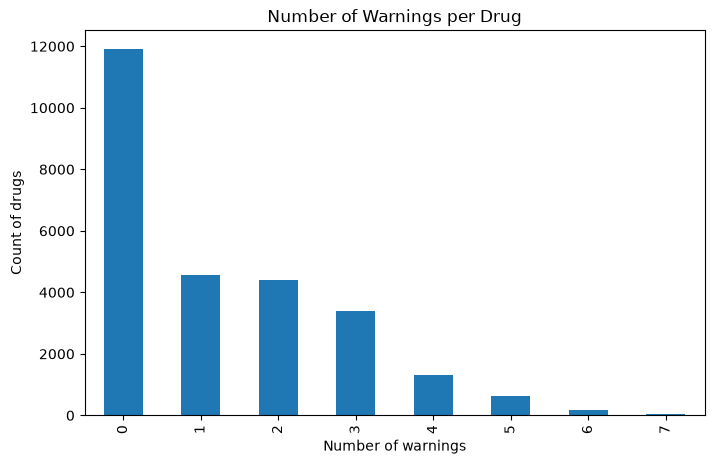

In [22]:
#number of warnings per drug
eg[warning_cols].sum(axis=1).value_counts().sort_index().plot(kind='bar', figsize=(8, 5))
plt.title('Number of Warnings per Drug')
plt.xlabel('Number of warnings')
plt.ylabel('Count of drugs')
plt.show()

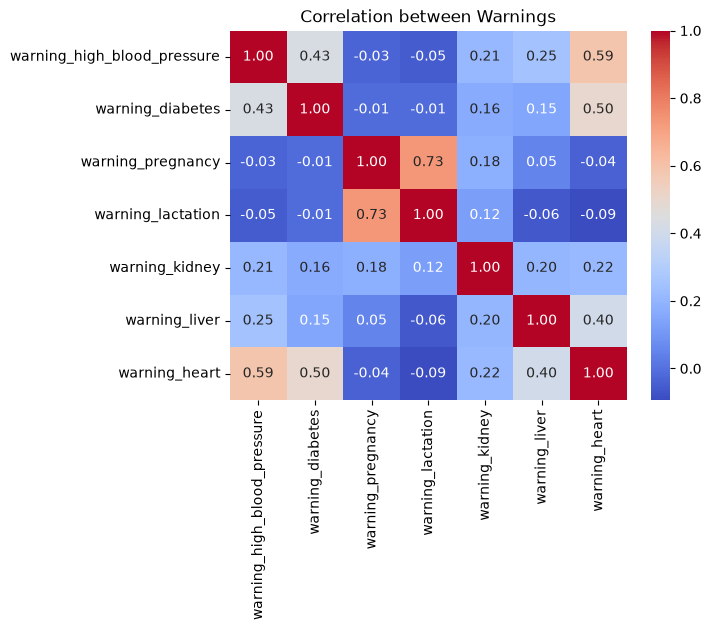

In [23]:
#correlation between warnings
sns.heatmap(eg[warning_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation between Warnings')
plt.show()

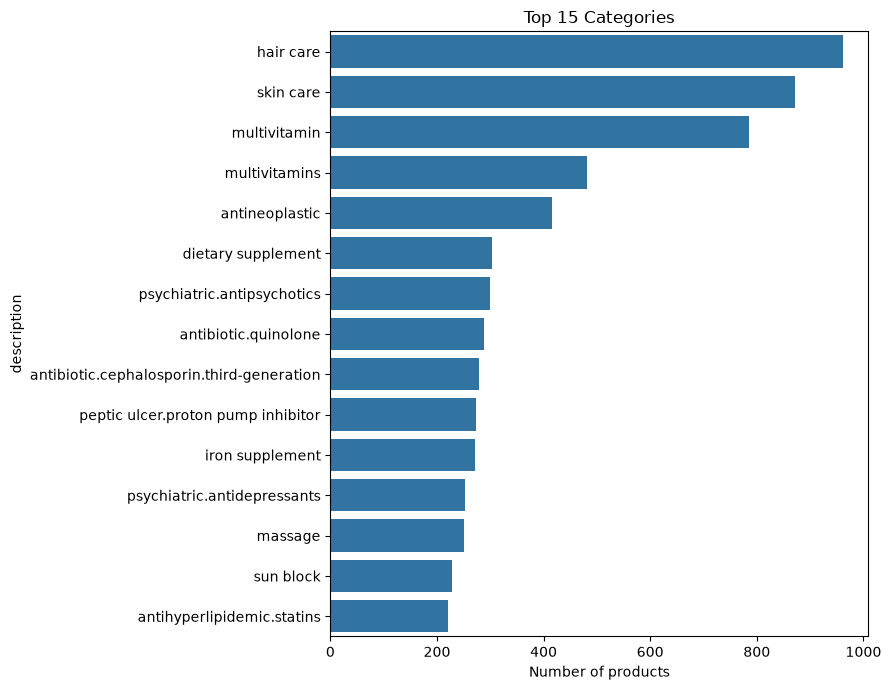

In [24]:
top_desc = eg.loc[eg['description'] != 'notfound','description'].value_counts().head(15)

plt.figure(figsize=(9, 7))
sns.barplot(x=top_desc.values, y=top_desc.index)
plt.title('Top 15 Categories')
plt.xlabel('Number of products')
plt.tight_layout()
plt.show()

In [25]:
#save cleaned data
eg.to_csv("../data/cleaned_eg_drugs.csv", index=False)

## Key Findings
- **Data size:** 26,562 drugs before cleaning, 26,430 after (removed rows with zero/missing price and duplicate names).
- **Price:** median price is 79 EGP while the mean is about 1,920 EGP, so the distribution is heavily right-skewed. 58% of drugs cost 100 EGP or less, and only 3.6% cost more than 1,000 EGP. The highest price (34 million EGP) is a real gene therapy drug, so extreme prices were kept.
- **Warnings:** the most common warning is pregnancy (26.6%), then kidney (23.5%) and heart (20.0%). The least common is diabetes (11.8%).
- **Multiple warnings:** about 45% of drugs have no warnings; the rest have between 1 and 7.
- **Correlation:** high blood pressure and heart warnings are the most related (0.59).
- **Active ingredients:** 8,946 unique values; the most common is amoxicillin+clavulanic acid (122 drugs).
- **Categories:** the biggest categories are hair care (961) and skin care (871).
